# huMAP2 confidence notebook

## What the confidence cutoffs change

In the saved run, huMAP2 has **17,361,543** unique canonical edges. A minimum score of **0.05** retains **27,082 edges** across **8,856 incident accessions**. Raising the cutoff to **0.95** retains **6,914 edges** across **3,320 incident accessions**, about one quarter of the edges that pass 0.05.

## Setup

Open this notebook from the repository root or its notebooks directory with a Jupyter kernel that has the project dependencies, ipykernel, and Matplotlib. Change the custom cutoff or primary accession below to explore the prepared graph.

In [1]:
from hashlib import file_digest
from html import escape
from io import BytesIO
import json
from pathlib import Path
import sys

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import polars as pl

cwd = Path.cwd()
root = next((path for path in (cwd, *cwd.parents) if (path / "networks.py").is_file()), None)
if root is None:
    raise FileNotFoundError("Open the notebook from the interactome repository.")
sys.path.insert(0, str(root))

from networks import discover_datasets, network_source_path, scan_humap_source, source_endpoint_profile, threshold_curve

data_root = root / "data"
datasets = discover_datasets(data_root)
source = network_source_path(data_root, "huMAP2")
canonical_path = datasets.get("huMAP2")
if canonical_path is None:
    raise FileNotFoundError("Prepare huMAP2 as described in the repository README before rerunning.")

standard_cutoffs = (0.05, 0.95)
custom_cutoff = 0.50  # Change this to any value from 0 to 1.
accession = "P04637"  # Query a primary accession.
preview_rows = 6


def sha256(path):
    with path.open("rb") as handle:
        return file_digest(handle, "sha256").hexdigest()


def show_table(frame):
    def table_row(values):
        fields = [
            f"{value:,}" if isinstance(value, int) else escape(str(value)).replace("|", r"\|")
            for value in values
        ]
        return "| " + " | ".join(fields) + " |"

    rows = [frame.columns, ["---"] * frame.width, *frame.rows()]
    display(Markdown("\n".join(map(table_row, rows))))

## Read the source and its preparation audit

The inputs are the headerless archive at `data/raw_networks/humap2_ppis_ACC_20200821.pairsWprob.gz` and the prepared graph and audit at `data/processed_networks/huMAP2.{parquet,json}`. The notebook reads these files and recomputes retention and partner counts locally.

The preparation resolves endpoints to human UniProt primary accessions, collapses numeric isoform suffixes, and expands multiple mapped targets. It drops source and mapped self-loops, excludes invalid scores, and keeps the highest valid score per undirected pair.

In [2]:
raw = scan_humap_source(source)
source_ids, source_rows, isoform_rows = source_endpoint_profile(raw)
audit = json.loads(canonical_path.with_suffix(".json").read_text(encoding="utf-8"))

source_sha = sha256(source)
canonical_sha = sha256(canonical_path)
assert audit["source"]["sha256"] == source_sha, "The raw source differs from the preparation audit."
assert audit["output"]["sha256"] == canonical_sha, "The prepared Parquet differs from its audit."
assert audit["input_rows"] == source_rows

show_table(raw.head(preview_rows).collect().rename({
    "a": "Source A", "b": "Source B", "probability": "Native score",
}))
display(Markdown(
    f"The raw archive has **{len(source_ids):,} distinct IDs** and "
    f"**{isoform_rows:,} rows with at least one explicit isoform suffix**."
))
display(Markdown(
    f"- Raw archive SHA-256 `{source_sha}`\n"
    f"- Canonical Parquet SHA-256 `{canonical_sha}`\n"
    f"- Mapping SHA-256 recorded at preparation `{audit['mapping_sha256']}`"
))

| Source A | Source B | Native score |
| --- | --- | --- |
| P46926 | Q8TDQ7 | 1.0 |
| P43631 | Q14954 | 1.0 |
| P43631 | Q14953 | 1.0 |
| P43631 | P43629 | 1.0 |
| 100287045 | Q86YD7 | 1.0 |
| 100287362 | Q9UI38 | 1.0 |

The raw archive has **15,373 distinct IDs** and **4,991 rows with at least one explicit isoform suffix**.

- Raw archive SHA-256 `11711484a41540a11e725a2ebb8b073b1322a3d4b894f26446ac3deeae14a0f3`
- Canonical Parquet SHA-256 `0eeaca087313d4c6f940a041271880812c6c4572e114c077a6542cc1fb6047b2`
- Mapping SHA-256 recorded at preparation `5be46f166be466516e56ed0988079afd97c0421b074751192c5eebd63e453c6b`

### Preparation counts

Mapping can expand one source row into several canonical candidates. The counts describe successive stages and diagnostics at different grains. The duplicate count is measured after removing mapped self-loops and invalid scores.

In [3]:
duplicate_rows = (
    audit["expanded_mapped_rows"] - audit["self_loop_rows"]
    - audit["invalid_score_rows"] - audit["edges"]
)
show_table(pl.DataFrame({
    "Stage or diagnostic": [
        "Source rows", "Source self-loop rows", "Rows with an unresolved endpoint",
        "Source IDs mapped to multiple targets", "Rows after mapping and expansion",
        "Mapped self-loop rows", "Mapped rows with invalid scores",
        "Duplicate canonical rows removed", "Unique canonical edges", "Incident accessions",
    ],
    "Count": [
        source_rows, audit["source_self_loop_rows"], audit["unmapped_edge_rows"],
        audit["one_to_many_id_count"], audit["expanded_mapped_rows"],
        audit["self_loop_rows"], audit["invalid_score_rows"], duplicate_rows,
        audit["edges"], audit["nodes"],
    ],
}))

| Stage or diagnostic | Count |
| --- | --- |
| Source rows | 17,526,311 |
| Source self-loop rows | 21 |
| Rows with an unresolved endpoint | 179,593 |
| Source IDs mapped to multiple targets | 106 |
| Rows after mapping and expansion | 17,492,697 |
| Mapped self-loop rows | 249 |
| Mapped rows with invalid scores | 0 |
| Duplicate canonical rows removed | 130,905 |
| Unique canonical edges | 17,361,543 |
| Incident accessions | 15,713 |

## Compare confidence cutoffs

A cutoff retains every canonical edge whose native probability is greater than or equal to it. The score represents association confidence and has no p-value interpretation. Each node count covers only accessions incident to a retained edge. The base denominator is the full valid-score canonical graph at cutoff 0.

In [4]:
thresholds = sorted({*(step / 20 for step in range(21)), custom_cutoff})
retention = threshold_curve(data_root, thresholds=thresholds, name="huMAP2")
base = retention.row(0, named=True)
assert (base["edges"], base["nodes"]) == (audit["edges"], audit["nodes"])
standard = retention.filter(pl.col("threshold").is_in(standard_cutoffs))
show_table(
    retention.filter(pl.col("threshold").is_in([0.0, *standard_cutoffs, float(custom_cutoff)]))
    .select(
        pl.col("threshold").cast(pl.String).alias("Minimum score"),
        pl.col("edges").alias("Unique edges"),
        pl.col("nodes").alias("Incident accessions"),
        (pl.col("edges") * 100 / base["edges"]).round(4).cast(pl.String).add("%").alias("Base edges retained"),
    )
)

| Minimum score | Unique edges | Incident accessions | Base edges retained |
| --- | --- | --- | --- |
| 0.0 | 17,361,543 | 15,713 | 100.0% |
| 0.05 | 27,082 | 8,856 | 0.156% |
| 0.5 | 11,216 | 5,245 | 0.0646% |
| 0.95 | 6,914 | 3,320 | 0.0398% |

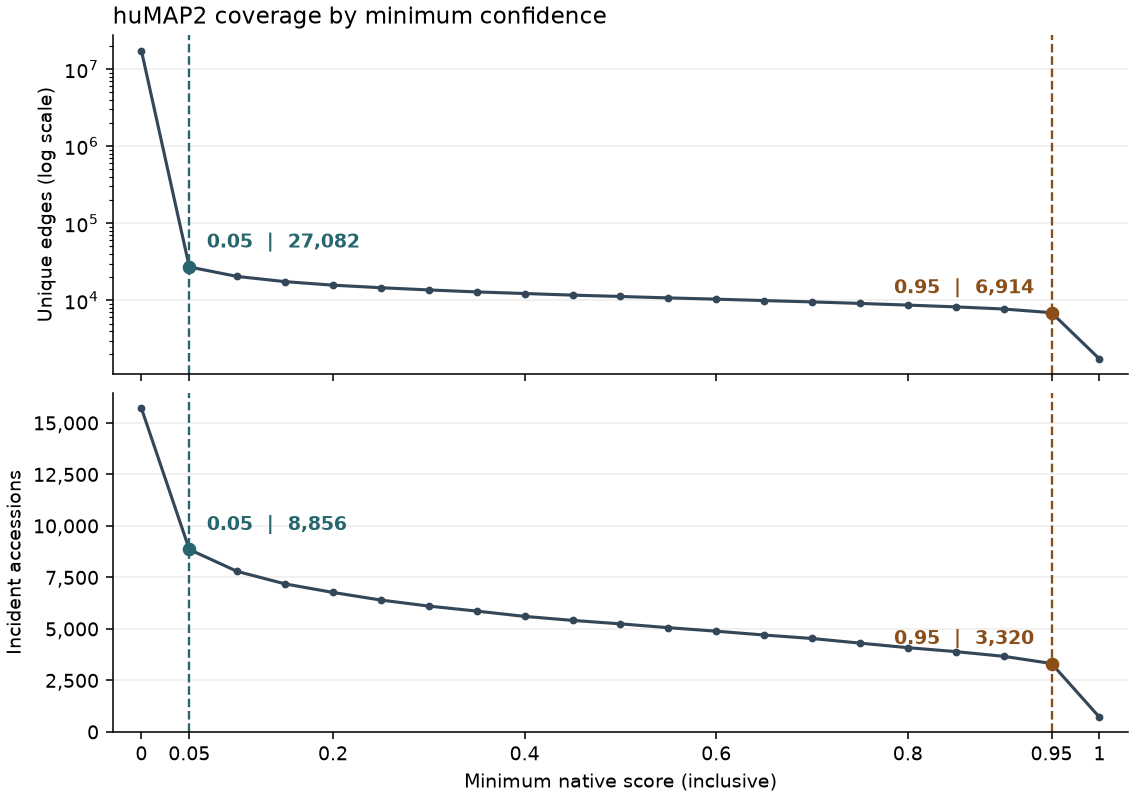

In [5]:
fig, (edge_ax, node_ax) = plt.subplots(
    2, 1, figsize=(8.1, 5.7), sharex=True, layout="constrained",
)
colors = ("#27666f", "#8a4e19")
for ax, metric, label in (
    (edge_ax, "edges", "Unique edges (log scale)"),
    (node_ax, "nodes", "Incident accessions"),
):
    plotted = retention.filter(pl.col(metric) > 0) if metric == "edges" else retention
    ax.plot(plotted["threshold"], plotted[metric], color="#344759", marker=".", linewidth=1.6)
    for index, (cutoff, color) in enumerate(zip(standard_cutoffs, colors)):
        count = standard.filter(pl.col("threshold") == cutoff)[metric].item()
        ax.axvline(cutoff, color=color, linestyle="--", linewidth=1.2)
        if count or metric == "nodes":
            ax.scatter(cutoff, count, color=color, zorder=3)
            ax.annotate(
                f"{cutoff:.2f}  |  {count:,}", (cutoff, count),
                xytext=(9 if index == 0 else -9, 10),
                textcoords="offset points", ha="left" if index == 0 else "right",
                color=color, fontweight="bold",
            )
    ax.set_ylabel(label)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
edge_ax.set_yscale("log")
edge_ax.set_title("huMAP2 coverage by minimum confidence", loc="left")
node_ax.set_ylim(bottom=0)
node_ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
node_ax.set(
    xlim=(-0.03, 1.03), xlabel="Minimum native score (inclusive)",
    xticks=[0, .05, .2, .4, .6, .8, .95, 1],
)
with BytesIO() as image:
    fig.savefig(image, format="png", dpi=140)
    display(Image(data=image.getvalue(), width=760), metadata={
        "alt": "Two plots show unique edges and incident accessions declining as the cutoff rises. "
               "Exact counts at 0.05 and 0.95 are labeled.",
    })
plt.close(fig)

Each point represents an evaluated cutoff. Zero edge counts are omitted from the log panel. A higher cutoff restricts the graph to higher-scoring pairs and reduces coverage. The curve describes that tradeoff and does not establish an optimal cutoff.

## Explore a primary accession

Change the accession and custom cutoff in the setup cell to inspect the strongest retained partners. The lookup scans the canonical Parquet and shows up to six partners in descending score order, with accession order breaking ties.

In [6]:
canonical = pl.scan_parquet(canonical_path)
partners = canonical.filter(
    ((pl.col("a") == accession) | (pl.col("b") == accession))
    & (pl.col("probability") >= custom_cutoff)
).select(
    pl.when(pl.col("a") == accession).then(pl.col("b")).otherwise(pl.col("a")).alias("Partner"),
    pl.col("probability").alias("Native score"),
).collect(engine="streaming")

display(Markdown(f"**{accession}** has **{partners.height:,} partners** at score ≥ **{custom_cutoff:g}**."))
show_table(
    partners.sort(["Native score", "Partner"], descending=[True, False])
    .head(preview_rows)
    .with_columns(pl.col("Native score").round(6))
)

**P04637** has **2 partners** at score ≥ **0.5**.

| Partner | Native score |
| --- | --- |
| Q8IWT3 | 0.995521 |
| O15151 | 0.914471 |

## Check the saved threshold graphs

For each standard cutoff, compare every retained pair and score with the corresponding saved version when the app discovers one with matching parent provenance. Independently confirm the edge and incident-accession counts against the retention calculation.

In [7]:
checks = []
for cutoff in standard_cutoffs:
    expected = standard.filter(pl.col("threshold") == cutoff).row(0, named=True)
    filtered = canonical.filter(pl.col("probability") >= cutoff).collect(engine="streaming")
    assert filtered.height == expected["edges"]
    assert pl.concat([filtered["a"], filtered["b"]]).n_unique() == expected["nodes"]
    assert filtered.filter(pl.col("a") >= pl.col("b")).is_empty()
    assert filtered.select("a", "b").n_unique() == filtered.height

    version_path = datasets.get(f"huMAP2_{cutoff:g}")
    status = "No matching saved version"
    if version_path is not None:
        version_audit = json.loads(version_path.with_suffix(".json").read_text(encoding="utf-8"))
        assert version_audit["output"]["sha256"] == sha256(version_path)
        assert version_audit["threshold"] == cutoff and version_audit["comparison"] == ">="
        assert filtered.sort("a", "b").equals(pl.read_parquet(version_path).sort("a", "b"))
        status = "All edges and scores match"
    checks.append({"Minimum score": cutoff, "Saved graph check": status})
show_table(pl.DataFrame(checks))

| Minimum score | Saved graph check |
| --- | --- |
| 0.05 | All edges and scores match |
| 0.95 | All edges and scores match |